<center>
  <h1> <strong> Interpretabilidade via Conjuntos Fuzzy </strong> </h1>
  <h3> U-Net(D2): grafeno </h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **Importação de bibliotecas**

In [60]:
import torch 
import pickle
import io
import os

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import to_rgb
import numpy as np
from sklearn.model_selection import train_test_split

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

import gc

In [61]:
import psutil

memoria = psutil.virtual_memory()

print(f"RAM total: {memoria.total / 1024**3:.2f} GB")
print(f"RAM disponível: {memoria.available / 1024**3:.2f} GB")
print(f"RAM utilizada: {memoria.percent}%")

RAM total: 15.68 GB
RAM disponível: 3.25 GB
RAM utilizada: 79.3%


### **Parâmetros do plot**

In [62]:
plt.rcParams.update({
    # "text.usetex": True,           
    "font.size": 12,                
    "axes.labelsize": 14,          
    "axes.titlesize": 16,
    "xtick.labelsize": 12,          
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
    "figure.dpi": 300,              
    "savefig.dpi": 300              
})

In [63]:
diretorio = "unetD2_final_grafeno"

In [64]:
os.makedirs(f"Imagens_interpretabilidade/{diretorio}", exist_ok=True)

In [65]:
cmap_3 = ListedColormap(["#F0E442", "#D55E00", "black"])

In [66]:
import torch.nn.functional as F
def restore_size(x, size):
    x = torch.tensor(x, dtype=torch.float32)

    # Redimensiona as duas últimas dimensões
    x = F.interpolate(
        x,
        size=size,
        mode="nearest"
    )
    return x.numpy()

### **Carregamento dos dados**

In [67]:
dados_grafeno = np.load(
        "../../Datasets_finais/graphene_test_final.npz"
        )

imagens_grafeno = dados_grafeno["image"].astype(np.float32)

del dados_grafeno

imagens_teste_grafeno = torch.from_numpy(imagens_grafeno)

imagens_teste_grafeno = imagens_teste_grafeno[0]

del imagens_grafeno

if imagens_teste_grafeno.ndim == 3:

    imagens_teste_grafeno = imagens_teste_grafeno.unsqueeze(1)

gc.collect()

82489

Text(0.5, 1.0, 'Imagem de Amostra - Grafeno')

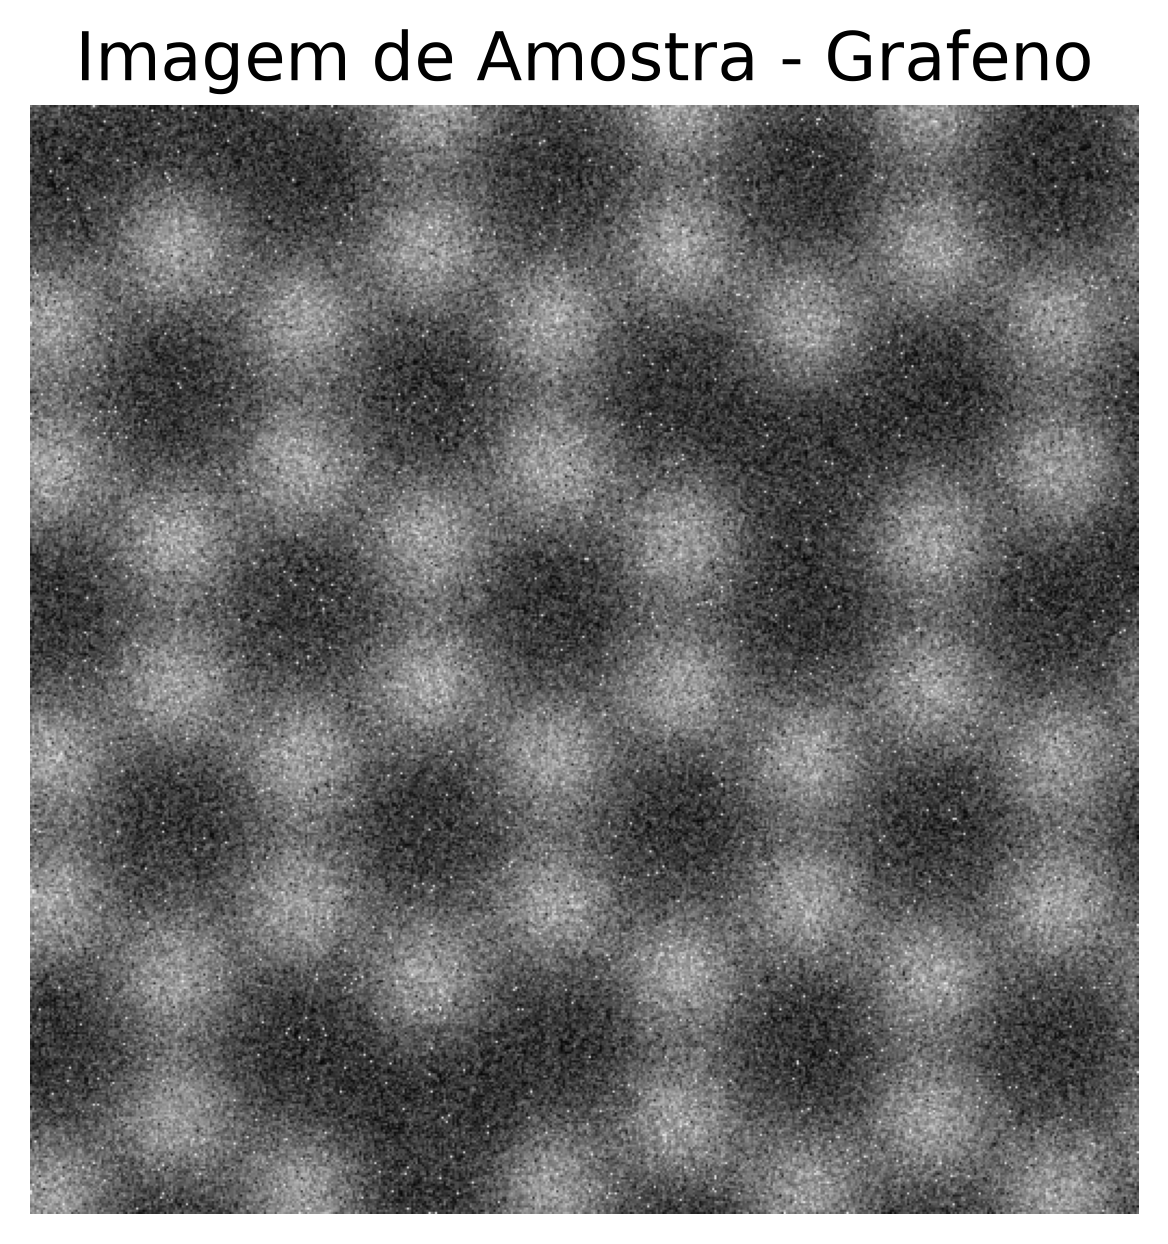

In [68]:
plt.axis("off")
plt.imshow(imagens_teste_grafeno[0,:,:][0], cmap='gray', vmin=0, vmax=1)

plt.title("Imagem de Amostra - Grafeno")

### **U-Net MaxPool Grafeno (Otimizada)**

In [69]:
# Salva a função original
_load_from_bytes_original = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("../3_Otimização-de-Hiperparâmetros/3_3_Redes-Treinadas/3_3_1_grafeno/U_Net_MaxPool_grafeno_dados_completos.pkl", "rb") as modelo:
        UNet_grafeno_otimizada = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original

UNet_grafeno_otimizada = UNet_grafeno_otimizada.to("cpu")
UNet_grafeno_otimizada.eval()

UNet_BinariaD2(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): SiLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_s

### Max Pooling 1

In [70]:
convolucao1 = UNet_grafeno_otimizada.down1(
    imagens_teste_grafeno
)

teste_conv_MP1 = UNet_grafeno_otimizada.pool1(convolucao1)

imagens_conv1 = convolucao1.detach().cpu().numpy()
imagens_pool1 = teste_conv_MP1.detach().cpu().numpy()

In [71]:
print("MAX POOLING 1 \n")

i = 0  # Única imagem

crms_conv1 = np.zeros((1, 16))
crms_MP1 = np.zeros((1, 16))
psnr1 = np.zeros((1, 16))
ssim1 = np.zeros((1, 16))

pool1_rsz = restore_size(imagens_pool1, (512, 512))

for c in range(16):

    crms_conv1[i, c] = np.std(
        imagens_conv1[i, c],
        ddof=0
    )

    crms_MP1[i, c] = np.std(
        pool1_rsz[i, c],
        ddof=0
    )

    psnr1[i, c] = peak_signal_noise_ratio(
        imagens_conv1[i, c],
        pool1_rsz[i, c],
        data_range=6
    )

    ssim1[i, c] = structural_similarity(
        imagens_conv1[i, c],
        pool1_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv1[i]), 4))
print("Crms Médio (MP): ", round(np.mean(crms_MP1[i]), 4))
print("PSNR Médio: ", round(np.mean(psnr1[i]), 4))
print("SSIM Médio: ", round(np.mean(ssim1[i]), 4))
print(" ")


MAX POOLING 1 

Imagem  0
Crms Médio (conv):  0.3572
Crms Médio (MP):  0.3956
PSNR Médio:  33.4823
SSIM Médio:  0.7612
 


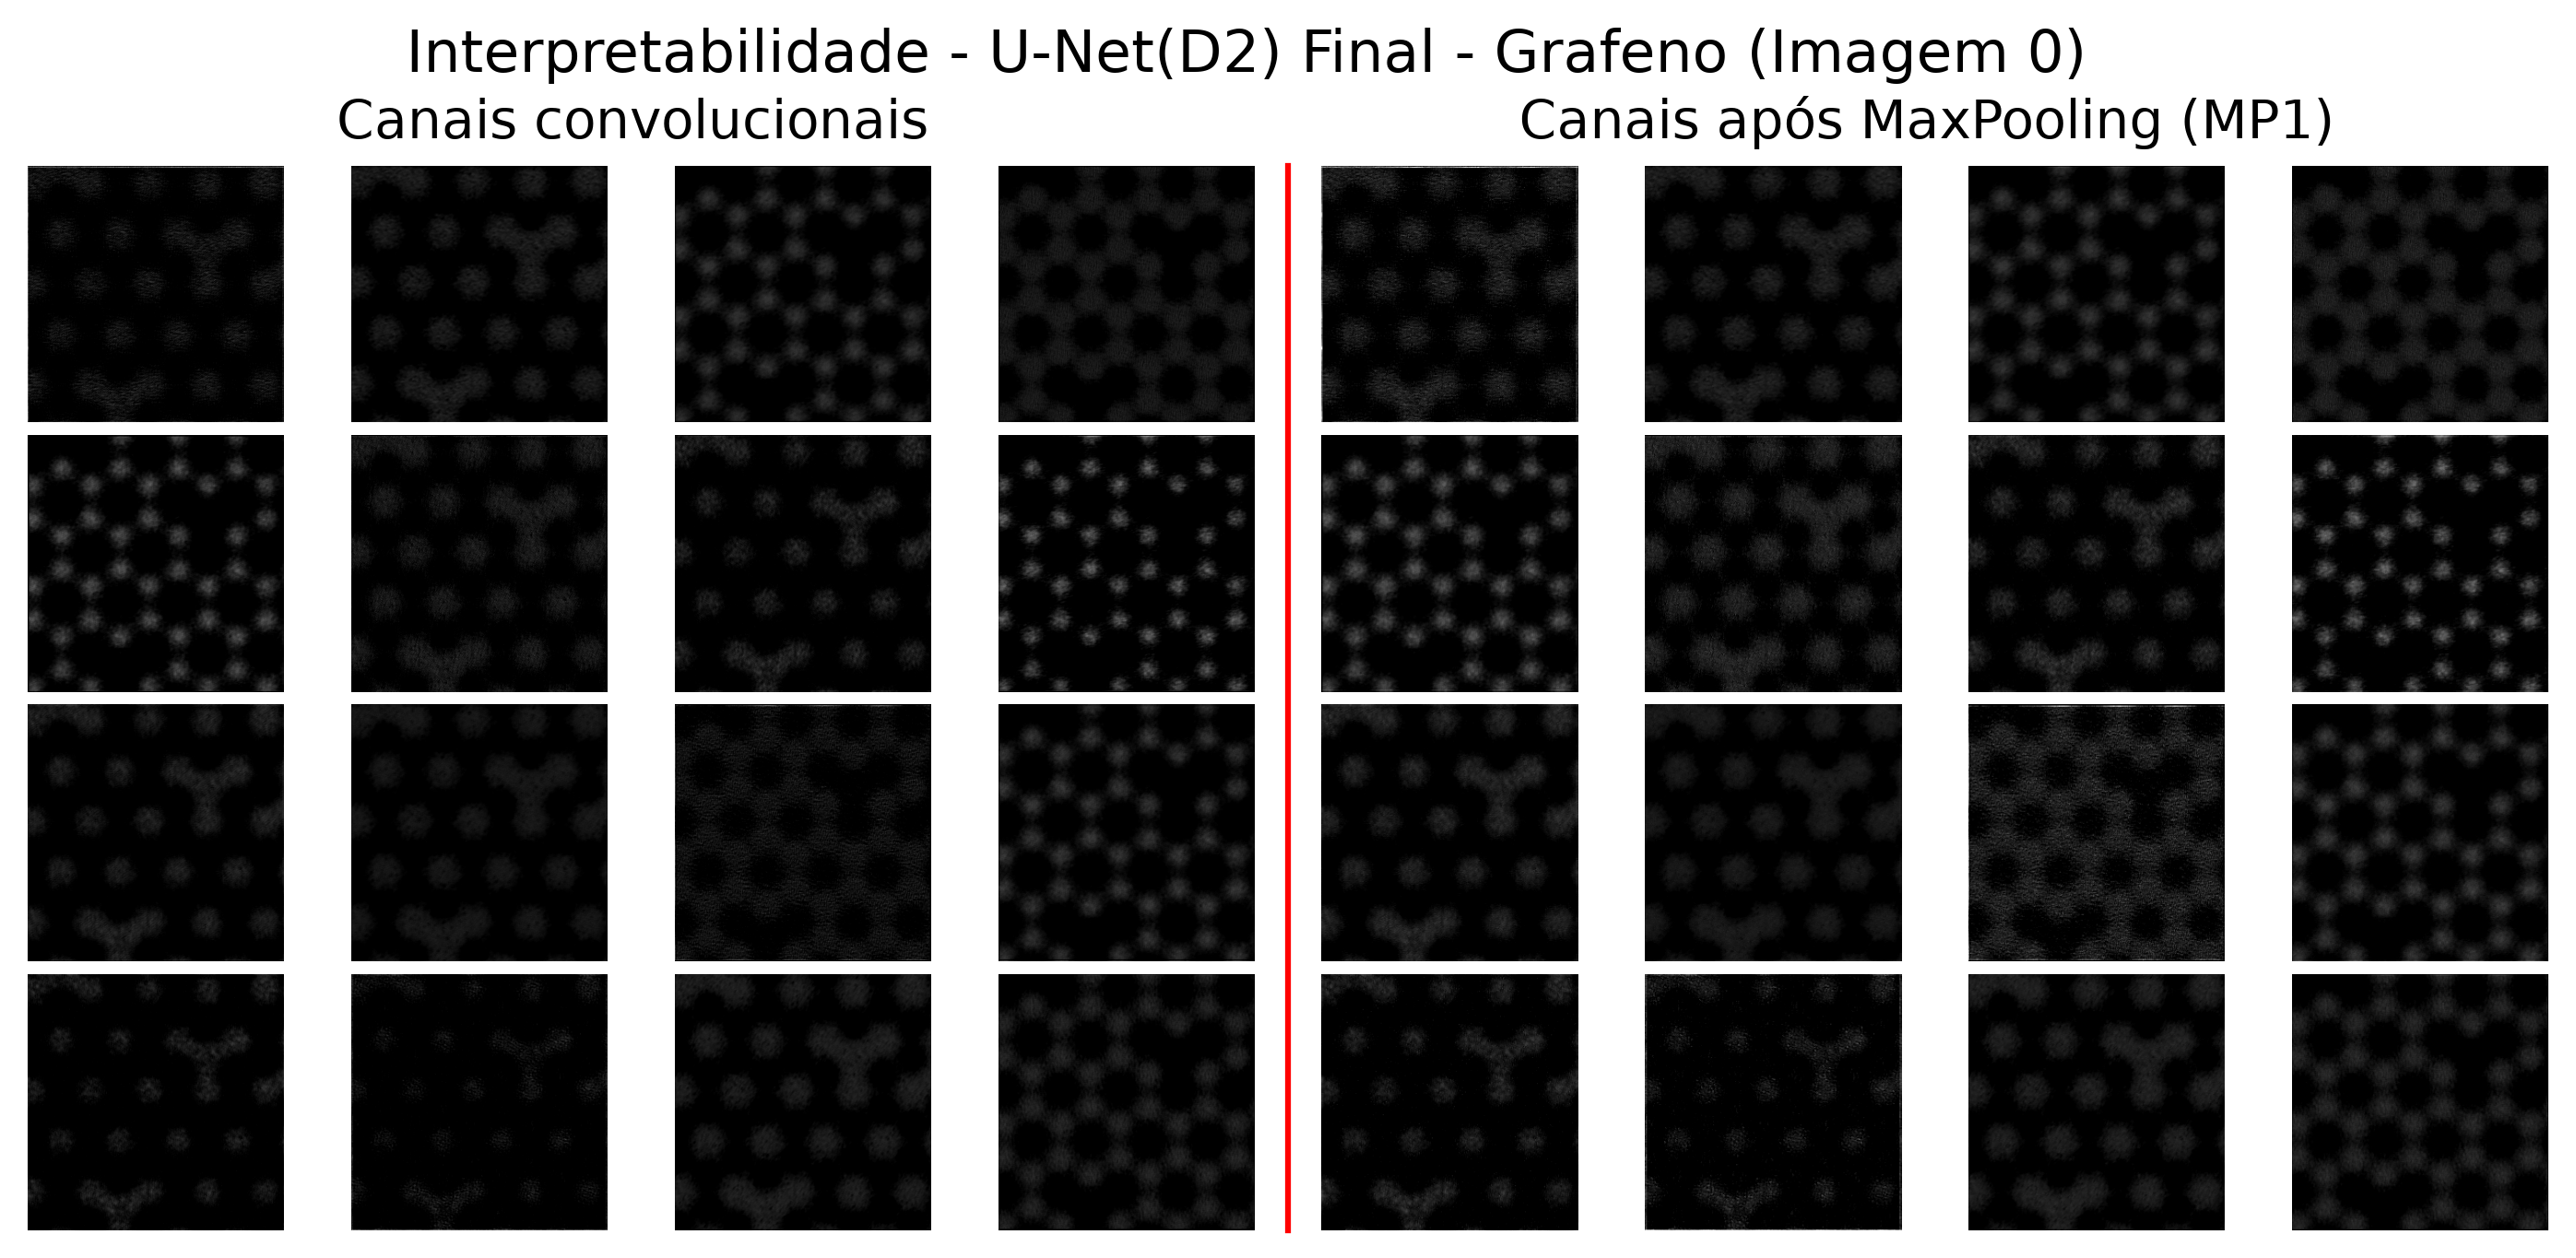

In [72]:
j = 0

fig, axes = plt.subplots(
    4, 8,
    figsize=(12, 5)
)

for i in range(16):

    linha = i // 4
    coluna = i % 4

    # Canais convolucionais
    axes[linha, coluna].imshow(
        imagens_conv1[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # Saída após FuzzyPooling
    axes[linha, coluna + 4].imshow(
        imagens_pool1[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 4].axis("off")

fig.suptitle(
    "Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)",
    fontsize=15
)

fig.text(
    0.315, 0.90,
    "Canais convolucionais",
    ha="center",
    fontsize=14,
)

fig.text(
    0.705, 0.90,
    "Canais após MaxPooling (MP1)",
    ha="center",
    fontsize=14,
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

x_separacao = (
    axes[0, 3].get_position().x1 +
    axes[0, 4].get_position().x0
) / 2

y_inferior = axes[3, 0].get_position().y0
y_superior = axes[0, 0].get_position().y1

fig.add_artist(
    plt.Line2D(
        [x_separacao, x_separacao],
        [y_inferior, y_superior],
        transform=fig.transFigure,
        color="red",
        linewidth=1.5
    )
)


plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/MP1_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Max Pooling 2

In [73]:
convolucao2 = UNet_grafeno_otimizada.down2(teste_conv_MP1)
teste_conv_MP2 = UNet_grafeno_otimizada.pool2(convolucao2)

imagens_conv2 = convolucao2.detach().cpu().numpy()
imagens_pool2 = teste_conv_MP2.detach().cpu().numpy()

In [74]:
print("MAX POOLING 2 \n")

i = 0  # Única imagem

crms_conv2 = np.zeros((1, 16))
crms_MP2 = np.zeros((1, 16))
psnr2 = np.zeros((1, 16))
ssim2 = np.zeros((1, 16))

pool2_rsz = restore_size(imagens_pool2, (256, 256))

for c in range(16):

    crms_conv2[i, c] = np.std(
        imagens_conv2[i, c],
        ddof=0
    )

    crms_MP2[i, c] = np.std(
        pool2_rsz[i, c],
        ddof=0
    )

    psnr2[i, c] = peak_signal_noise_ratio(
        imagens_conv2[i, c],
        pool2_rsz[i, c],
        data_range=6
    )

    ssim2[i, c] = structural_similarity(
        imagens_conv2[i, c],
        pool2_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv2[i]), 4))
print("Crms Médio (MP): ", round(np.mean(crms_MP2[i]), 4))
print("PSNR Médio: ", round(np.mean(psnr2[i]), 4))
print("SSIM Médio: ", round(np.mean(ssim2[i]), 4))
print(" ")

MAX POOLING 2 

Imagem  0
Crms Médio (conv):  0.3064
Crms Médio (MP):  0.3266
PSNR Médio:  37.4985
SSIM Médio:  0.9162
 


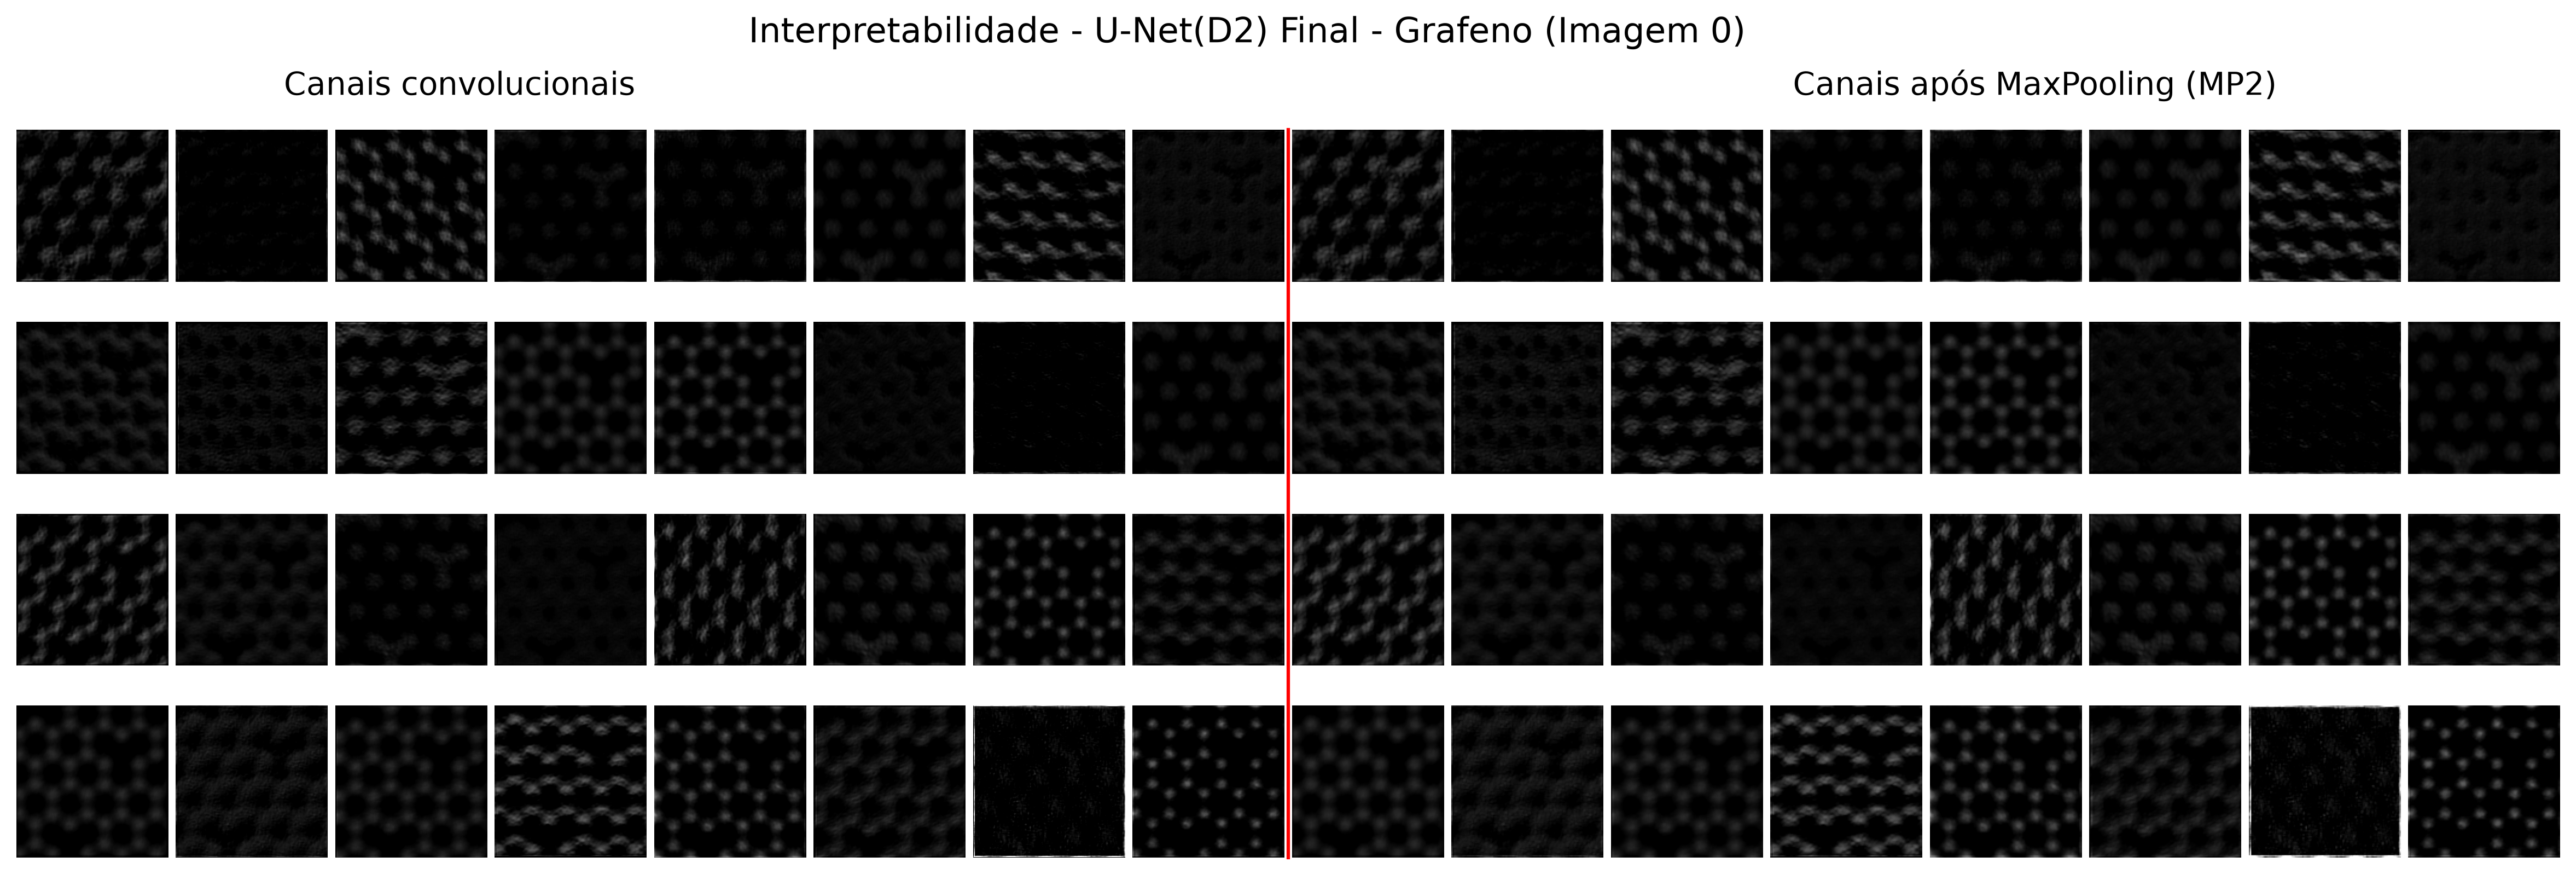

In [75]:
j = 0

fig, axes = plt.subplots(
    4, 16,
    figsize=(20, 6)
)

for i in range(32):

    linha = i // 8
    coluna = i % 8

    # Canais convolucionais
    axes[linha, coluna].imshow(
        imagens_conv2[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # Saída após MaxPooling
    axes[linha, coluna + 8].imshow(
        imagens_pool2[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 8].axis("off")

fig.suptitle(
    "Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)",
    fontsize=15
)

fig.text(
    0.26, 0.90,
    "Canais convolucionais",
    ha="center",
    fontsize=14
)

fig.text(
    0.74, 0.90,
    "Canais após MaxPooling (MP2)",
    ha="center",
    fontsize=14
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

# Linha separatória
x_separacao = (
    axes[0, 7].get_position().x1 +
    axes[0, 8].get_position().x0
) / 2

y_inferior = axes[3, 0].get_position().y0
y_superior = axes[0, 0].get_position().y1

fig.add_artist(
    plt.Line2D(
        [x_separacao, x_separacao],
        [y_inferior, y_superior],
        transform=fig.transFigure,
        color="red",
        linewidth=1.5
    )
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/MP2_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Max Pooling 3

In [76]:
convolucao3 = UNet_grafeno_otimizada.down3(teste_conv_MP2)
teste_conv_MP3 = UNet_grafeno_otimizada.pool3(convolucao3)

imagens_conv3 = convolucao3.detach().cpu().numpy()
imagens_pool3 = teste_conv_MP3.detach().cpu().numpy()

In [77]:
print("Max POOLING 3 \n")

crms_conv3 = np.zeros((1, 64)) # imagem, canal
crms_MP3 = np.zeros((1, 64))
psnr3 = np.zeros((1, 64)) 
ssim3 = np.zeros((1, 64))

pool3_rsz = restore_size(imagens_pool3, (128, 128))

i= 0 

for c in range(64):
    crms_conv3[i, c] = np.std(imagens_conv3[i, c], correction=0)
    crms_MP3[i, c] = np.std(pool3_rsz[i, c], correction=0)
    
    psnr3[i, c] = peak_signal_noise_ratio(
        imagens_conv3[i, c],
        pool3_rsz[i, c],
        data_range=6
    )

    ssim3[i, c] = structural_similarity(
        imagens_conv3[i, c],
        pool3_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv3[i]),4))
print("Crms Médio (MP): ", round(np.mean(crms_MP3[i]),4))
print("PSNR Médio: ", round(np.mean(psnr3[i]),4))
print("SSIM Médio: ", round(np.mean(ssim3[i]),4))
print(" ")

Max POOLING 3 

Imagem  0
Crms Médio (conv):  0.4278
Crms Médio (MP):  0.468
PSNR Médio:  31.0733
SSIM Médio:  0.7407
 


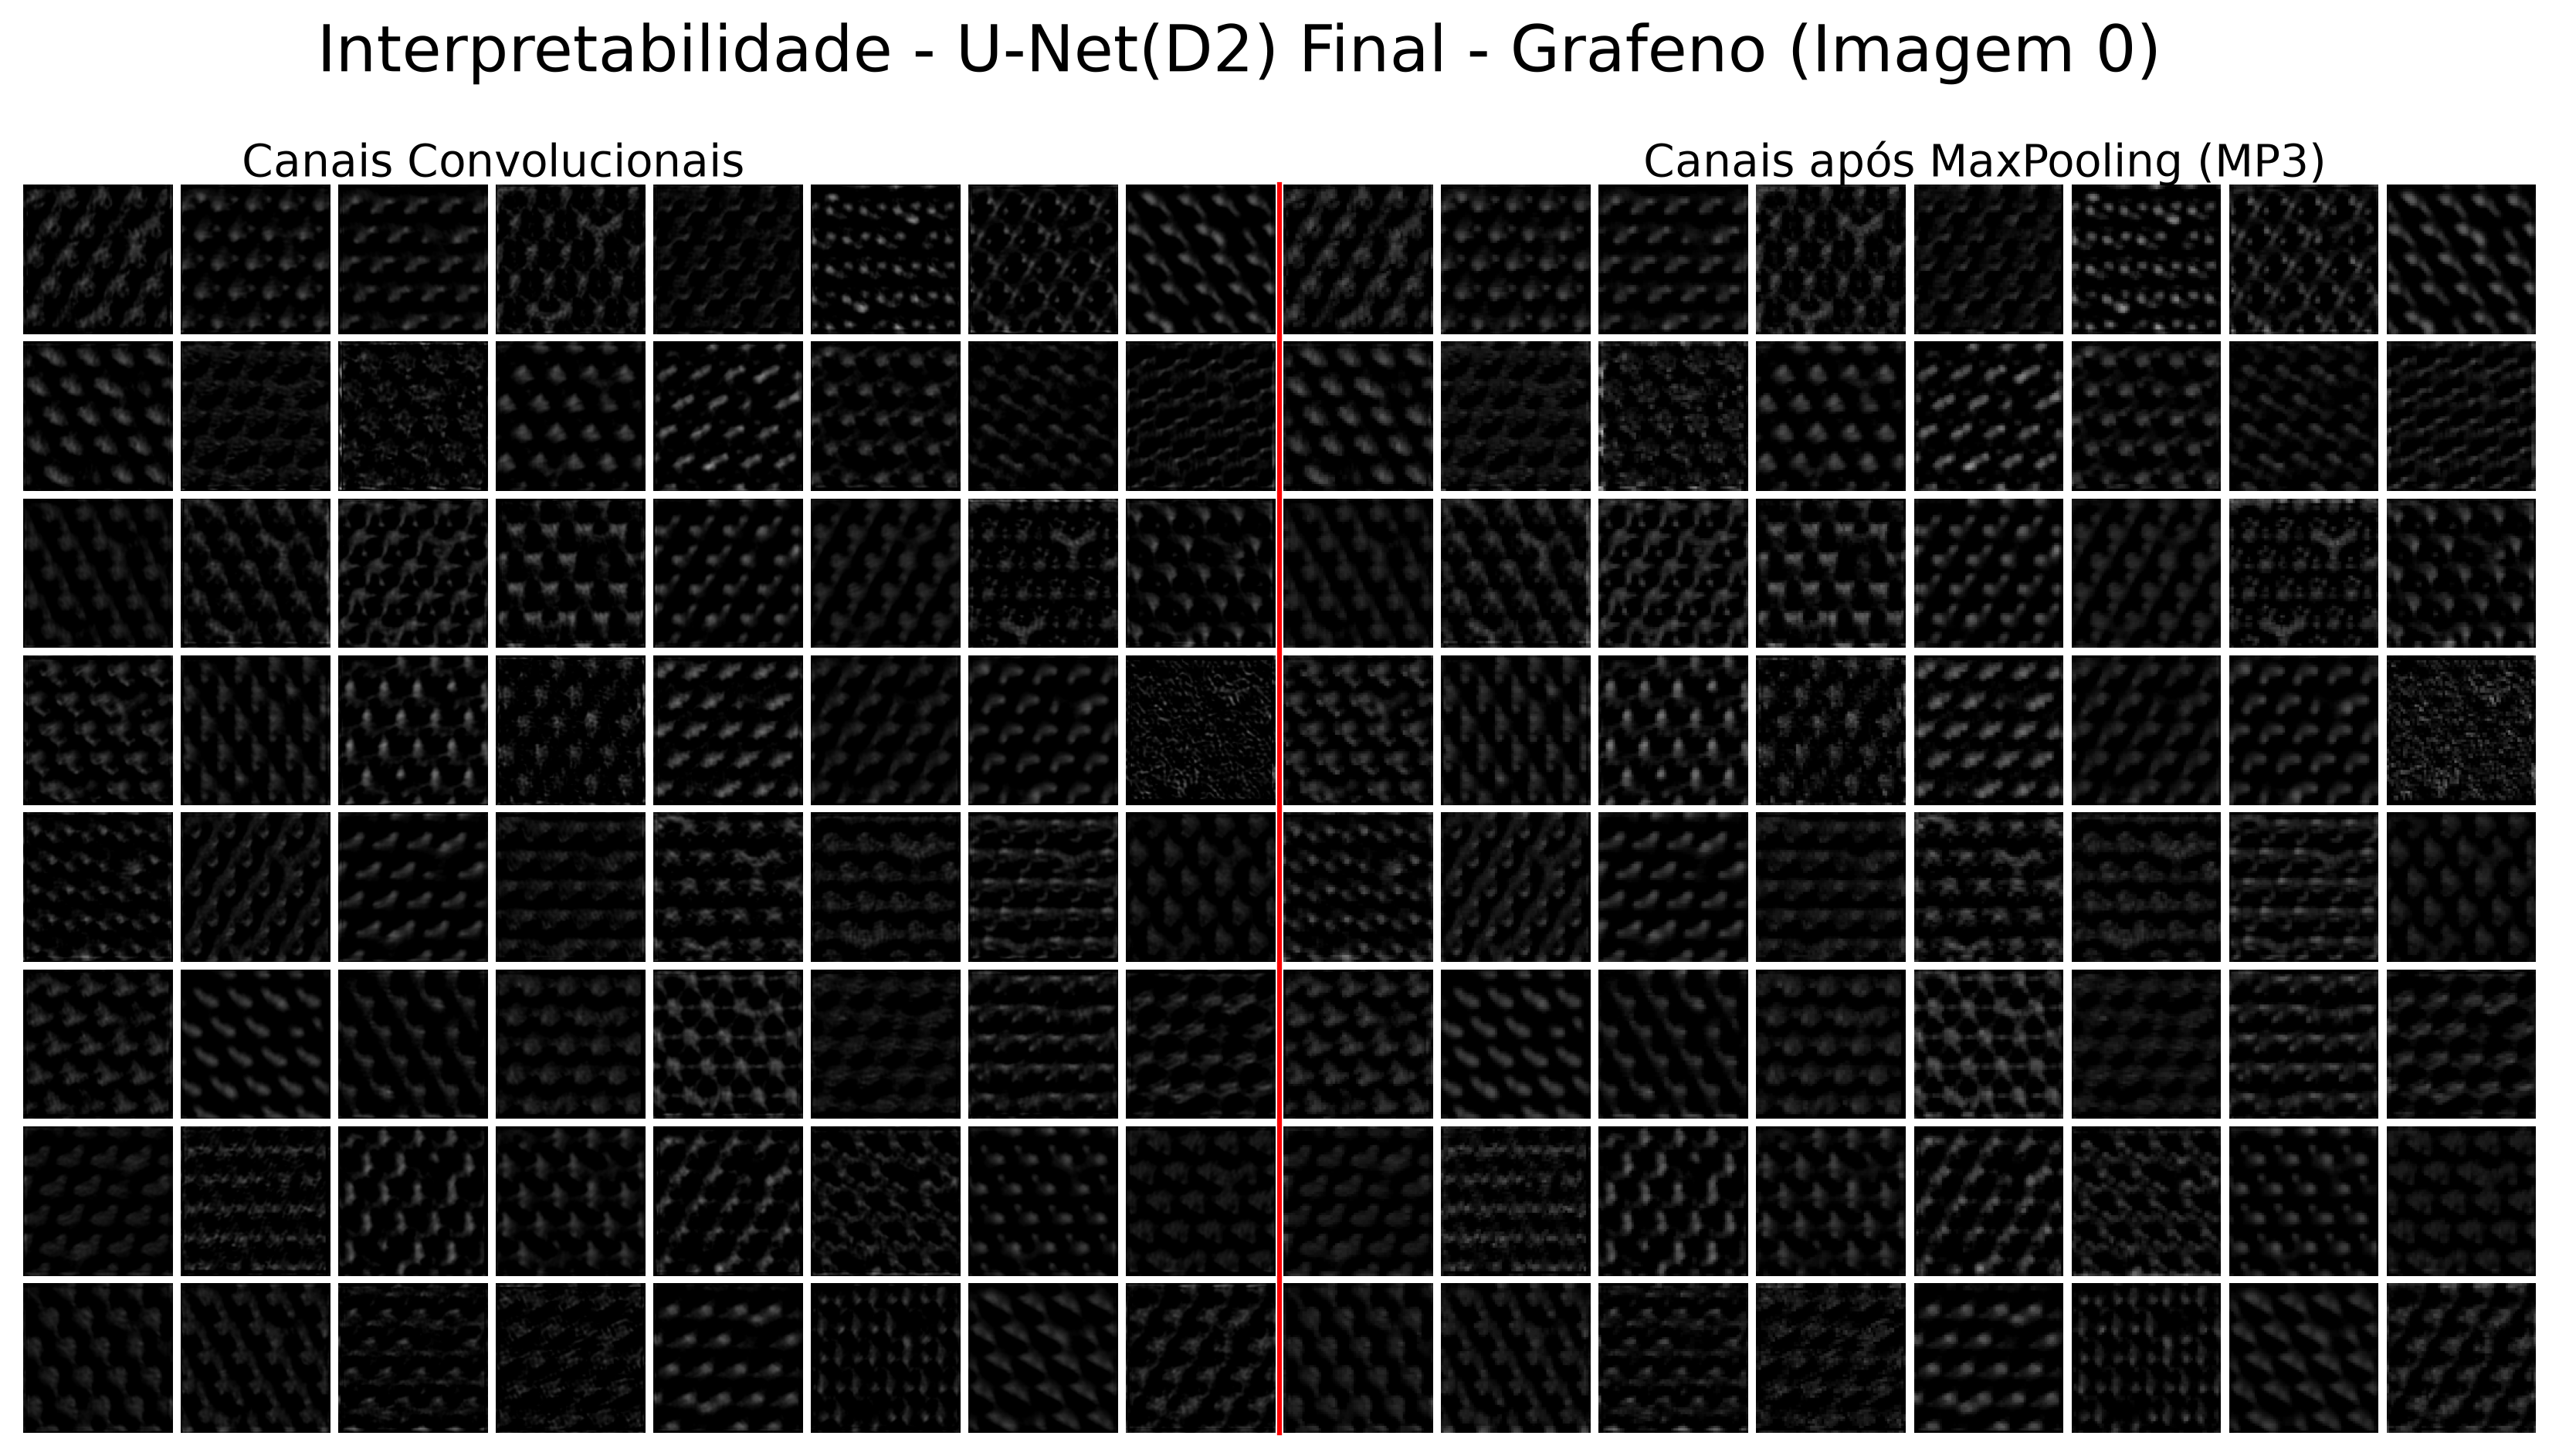

In [78]:
fig, axes = plt.subplots(8, 16, figsize=(14, 7))

for i in range(64):

    linha = i // 8
    coluna = i % 8

    # Convoluções
    axes[linha, coluna].imshow(
        imagens_conv3[0, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # MaxPooling
    axes[linha, coluna + 8].imshow(
        pool3_rsz[0, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 8].axis("off")

fig.suptitle(
    f"Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)",
    fontsize=20
)

fig.text(
    0.27, 0.885,
    "Canais Convolucionais",
    ha="center",
    fontsize=14
)

fig.text(
    0.73, 0.885,
    "Canais após MaxPooling (MP3)",
    ha="center",
    fontsize=14
)

# Linha separatória
x_separacao = (
    axes[0, 7].get_position().x1 +
    axes[0, 8].get_position().x0
) / 2

y_inferior = axes[7, 0].get_position().y0
y_superior = axes[0, 0].get_position().y1

fig.add_artist(
    plt.Line2D(
        [x_separacao, x_separacao],
        [y_inferior, y_superior],
        transform=fig.transFigure,
        color="red",
        linewidth=1.5
    )
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/MP3_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)